# Bài 5a (Trang 45) – Online Retail, nước Đức, min_sup = 5%, min_conf = 50%


In [1]:
# ===== Câu 1: Đọc dữ liệu vào chương trình =====
print("Nguyễn Bình Minh - 6451071047")

!pip install -q mlxtend==0.25.0 openpyxl > /dev/null 2>&1
import time
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

df = pd.read_excel('Online_Retail.xlsx')
df.info()

Nguyễn Bình Minh - 6451071047


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [2]:
# ===== Câu 2: Làm sạch Description, xóa dòng không có InvoiceNo, chuyển InvoiceNo về chuỗi =====
print("Nguyễn Bình Minh - 6451071047")

df['Description'] = df['Description'].str.strip()
df.dropna(axis=0, subset=['InvoiceNo'], inplace=True)
df['InvoiceNo'] = df['InvoiceNo'].astype('str')
display(df.head(10))

Nguyễn Bình Minh - 6451071047


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [3]:
# ===== Câu 3: Xóa các hóa đơn tín dụng (InvoiceNo chứa 'C') =====
print("Nguyễn Bình Minh - 6451071047")

display(df[df.InvoiceNo.str.contains('C', na=False)].head())
print('Số dòng hóa đơn tín dụng:', df.InvoiceNo.str.contains('C', na=False).sum())
df = df[~df['InvoiceNo'].str.contains('C')]
print('Số dòng còn lại:', len(df))

Nguyễn Bình Minh - 6451071047


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


Số dòng hóa đơn tín dụng: 9288
Số dòng còn lại: 532621


Nguyễn Bình Minh - 6451071047


Country
United Kingdom          487622
Germany                   9042
France                    8408
EIRE                      7894
Spain                     2485
Netherlands               2363
Belgium                   2031
Switzerland               1967
Portugal                  1501
Australia                 1185
Norway                    1072
Italy                      758
Channel Islands            748
Finland                    685
Cyprus                     614
Sweden                     451
Unspecified                446
Austria                    398
Denmark                    380
Poland                     330
Japan                      321
Israel                     295
Hong Kong                  284
Singapore                  222
Iceland                    182
USA                        179
Canada                     151
Greece                     145
Malta                      112
United Arab Emirates        68
European Community          60
RSA                         58


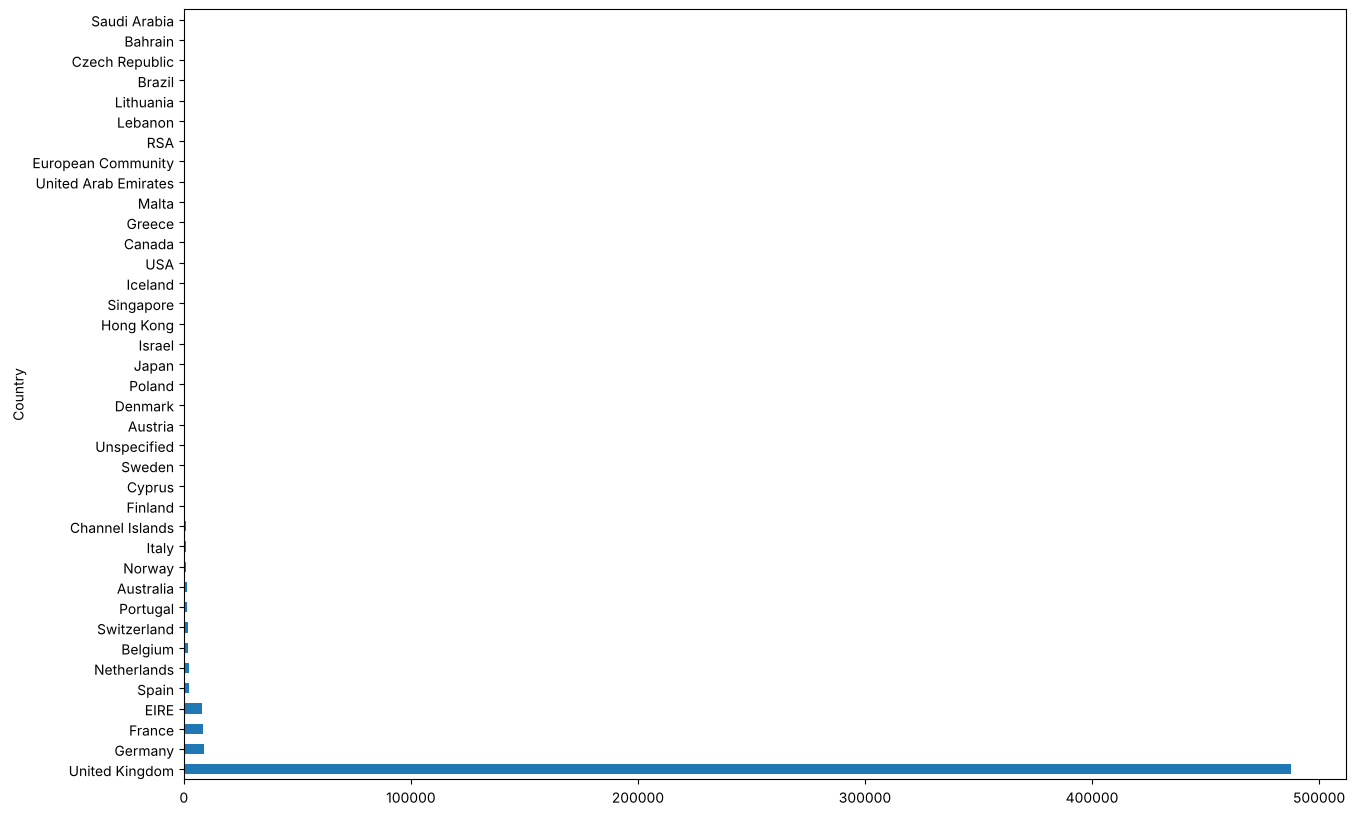

In [4]:
# ===== Câu 4: Thống kê số dòng dữ liệu theo từng quốc gia =====
print("Nguyễn Bình Minh - 6451071047")

print(df['Country'].value_counts())
df['Country'].value_counts().plot(kind='barh', figsize=(15, 10))
plt.show()

In [5]:
# ===== Câu 5: Lấy hóa đơn của 'Germany', gom nhóm Quantity theo InvoiceNo và Description =====
print("Nguyễn Bình Minh - 6451071047")

basket = df[df['Country'] == "Germany"].groupby(['InvoiceNo', 'Description'])['Quantity']
print('Số dòng của Germany:', (df['Country'] == "Germany").sum())
print('Số hóa đơn:', df[df['Country'] == "Germany"]['InvoiceNo'].nunique())

Nguyễn Bình Minh - 6451071047
Số dòng của Germany: 9042
Số hóa đơn: 457


In [6]:
# ===== Câu 6: Chuyển dữ liệu về dạng hot encoding, mỗi dòng là một hóa đơn =====
print("Nguyễn Bình Minh - 6451071047")

basket = basket.sum().unstack().reset_index().fillna(0).set_index('InvoiceNo')
print('Kích thước:', basket.shape)
display(basket.head(10))

Nguyễn Bình Minh - 6451071047
Kích thước: (457, 1695)


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536840,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536861,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536967,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
536983,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537197,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537198,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537201,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
537212,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [7]:
# ===== Câu 7: Chuyển từ hot encoding thành one-hot encoding =====
print("Nguyễn Bình Minh - 6451071047")

def encode_data(datapoint):
    if datapoint <= 0:
        return 0
    if datapoint >= 1:
        return 1

basket = basket.map(encode_data)   # pandas mới dùng .map thay cho .applymap
basket = basket.astype(bool)       # mlxtend khuyến nghị dữ liệu kiểu bool
display(basket.head(10))

Nguyễn Bình Minh - 6451071047


Description,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 IVORY ROSE PEG PLACE SETTINGS,12 MESSAGE CARDS WITH ENVELOPES,12 PENCIL SMALL TUBE WOODLAND,12 PENCILS SMALL TUBE RED RETROSPOT,12 PENCILS SMALL TUBE SKULL,12 PENCILS TALL TUBE POSY,12 PENCILS TALL TUBE RED RETROSPOT,12 PENCILS TALL TUBE SKULLS,...,YULETIDE IMAGES GIFT WRAP SET,ZINC HEART T-LIGHT HOLDER,ZINC STAR T-LIGHT HOLDER,ZINC BOX SIGN HOME,ZINC FOLKART SLEIGH BELLS,ZINC HEART LATTICE T-LIGHT HOLDER,ZINC METAL HEART DECORATION,ZINC T-LIGHT HOLDER STAR LARGE,ZINC T-LIGHT HOLDER STARS SMALL,ZINC WILLIE WINKIE CANDLE STICK
InvoiceNo,,,,,,,,,,,,,,,,,,,,,
536527,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536840,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536861,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536967,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
536983,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
537197,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
537198,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
537201,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
537212,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [8]:
# ===== Câu 8: Xóa cột 'POSTAGE' (cước phí trên mỗi hóa đơn) =====
print("Nguyễn Bình Minh - 6451071047")

print('Có cột POSTAGE:', 'POSTAGE' in basket.columns)
basket.drop('POSTAGE', inplace=True, axis=1, errors='ignore')
print('Kích thước sau khi xóa:', basket.shape)

Nguyễn Bình Minh - 6451071047
Có cột POSTAGE: True
Kích thước sau khi xóa: (457, 1694)


In [9]:
# ===== Câu 9: Tìm tập phổ biến bằng Apriori với min_sup = 5% =====
print("Nguyễn Bình Minh - 6451071047")

start = time.time()
itemsets = apriori(basket, min_support=0.05, use_colnames=True)
time_apriori = time.time() - start
print('Số tập phổ biến:', len(itemsets))
print('Thời gian Apriori: %.3f giây' % time_apriori)
display(itemsets.head(10))

Nguyễn Bình Minh - 6451071047
Số tập phổ biến: 59
Thời gian Apriori: 0.005 giây


,support,itemsets
0,0.102845,frozenset({6 RIBBONS RUSTIC CHARM})
1,0.070022,frozenset({ALARM CLOCK BAKELIKE PINK})
2,0.065646,frozenset({CHARLOTTE BAG APPLES DESIGN})
3,0.050328,frozenset({CHILDRENS CUTLERY DOLLY GIRL})
4,0.061269,frozenset({COFFEE MUG APPLES DESIGN})
5,0.063457,frozenset({FAWN BLUE HOT WATER BOTTLE})
6,0.072210,frozenset({GUMBALL COAT RACK})
7,0.056893,frozenset({IVORY KITCHEN SCALES})
8,0.063457,frozenset({JAM JAR WITH PINK LID})
9,0.091904,frozenset({JAM MAKING SET PRINTED})


In [10]:
# ===== Câu 10: Tạo luật kết hợp với min_conf = 50% và in ra các luật =====
print("Nguyễn Bình Minh - 6451071047")

rules = association_rules(itemsets, metric="confidence", min_threshold=0.5)
rules.info()

# Chuyển vế trái, vế phải từ frozenset về chuỗi
rules["antecedents"] = rules["antecedents"].apply(lambda x: ', '.join(list(x)))
rules["consequents"] = rules["consequents"].apply(lambda x: ', '.join(list(x)))

print('\nSố luật tìm được:', len(rules))
for i in range(len(rules)):
    print(rules.loc[i, 'antecedents'], ' ==> ', rules.loc[i, 'consequents'],
          ' [', round(rules.loc[i, 'support'], 4), ', ', round(rules.loc[i, 'confidence'], 4), ']')

Nguyễn Bình Minh - 6451071047
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   antecedents         8 non-null      object 
 1   consequents         8 non-null      object 
 2   antecedent support  8 non-null      float64
 3   consequent support  8 non-null      float64
 4   support             8 non-null      float64
 5   confidence          8 non-null      float64
 6   lift                8 non-null      float64
 7   representativity    8 non-null      float64
 8   leverage            8 non-null      float64
 9   conviction          8 non-null      float64
 10  zhangs_metric       8 non-null      float64
 11  jaccard             8 non-null      float64
 12  certainty           8 non-null      float64
 13  kulczynski          8 non-null      float64
dtypes: float64(12), object(2)
memory usage: 1.0+ KB

Số luật tìm được: 8
PLASTERS IN TIN CIRCUS

Nguyễn Bình Minh - 6451071047


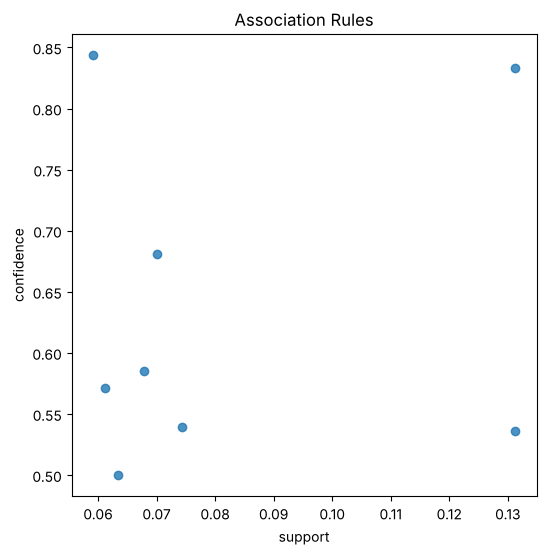

In [11]:
# ===== Câu 11: Biểu diễn độ hỗ trợ và độ tin cậy của tập luật (scatter plot) =====
print("Nguyễn Bình Minh - 6451071047")

support = rules['support'].values
confidence = rules['confidence'].values

plt.figure(figsize=(6, 6))
plt.title('Association Rules')
plt.xlabel('support')
plt.ylabel('confidence')
sns.regplot(x=support, y=confidence, fit_reg=False)
plt.show()

Nguyễn Bình Minh - 6451071047
ROUND SNACK BOXES SET OF 4 FRUITS  ==>  ROUND SNACK BOXES SET OF4 WOODLAND  [ 0.1313 ,  0.8333 ]
ROUND SNACK BOXES SET OF4 WOODLAND  ==>  ROUND SNACK BOXES SET OF 4 FRUITS  [ 0.1313 ,  0.5357 ]
WOODLAND CHARLOTTE BAG  ==>  ROUND SNACK BOXES SET OF4 WOODLAND  [ 0.0635 ,  0.5 ]
PLASTERS IN TIN CIRCUS PARADE  ==>  PLASTERS IN TIN WOODLAND ANIMALS  [ 0.0678 ,  0.5849 ]
SPACEBOY LUNCH BOX  ==>  ROUND SNACK BOXES SET OF4 WOODLAND  [ 0.07 ,  0.6809 ]
RED RETROSPOT CHARLOTTE BAG  ==>  WOODLAND CHARLOTTE BAG  [ 0.0591 ,  0.8438 ]
PLASTERS IN TIN WOODLAND ANIMALS  ==>  ROUND SNACK BOXES SET OF4 WOODLAND  [ 0.0744 ,  0.5397 ]
PLASTERS IN TIN SPACEBOY  ==>  PLASTERS IN TIN WOODLAND ANIMALS  [ 0.0613 ,  0.5714 ]



,Apriori,FP-Growth
Số tập phổ biến,59.000,59.000
Số luật,8.000,8.000
Thời gian (giây),0.005,0.011


Tập phổ biến giống nhau: True
Tập luật giống nhau   : True


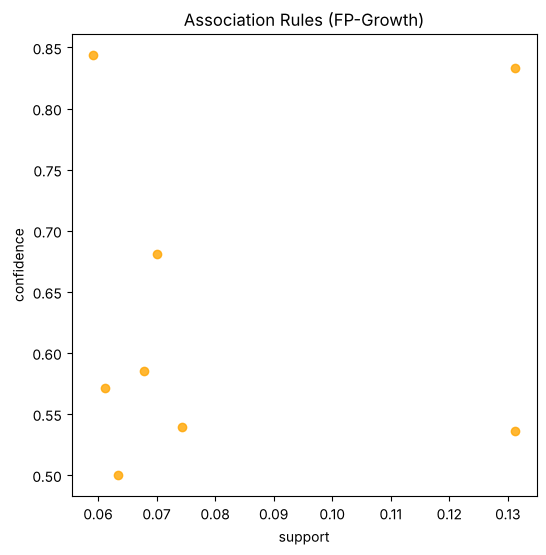


Nhận xét:
- Hai thuật toán cho cùng kết quả: 59 tập phổ biến và 8 luật kết hợp giống hệt nhau.
- Thời gian: Apriori 0.005s, FP-Growth 0.011s -> lần chạy này Apriori nhanh hơn.
- Dữ liệu nước Đức nhỏ (457 hóa đơn) nên cả hai đều chạy gần như tức thì, chênh lệch không đáng kể.
- Ưu thế của FP-Growth (không sinh tập ứng viên) chỉ thể hiện rõ khi dữ liệu lớn và min_sup nhỏ.
- Luật mạnh nhất: RED RETROSPOT CHARLOTTE BAG ==> WOODLAND CHARLOTTE BAG (confidence ~84%)
  và ROUND SNACK BOXES SET OF 4 FRUITS ==> ROUND SNACK BOXES SET OF4 WOODLAND (~83%).


In [12]:
# ===== Câu 12: FP-Growth với min_sup = 5%, min_conf = 50% và so sánh với Apriori =====
print("Nguyễn Bình Minh - 6451071047")

from mlxtend.frequent_patterns import fpgrowth

start = time.time()
itemsets_fp = fpgrowth(basket, min_support=0.05, use_colnames=True)
time_fp = time.time() - start
rules_fp = association_rules(itemsets_fp, metric="confidence", min_threshold=0.5)
rules_fp["antecedents"] = rules_fp["antecedents"].apply(lambda x: ', '.join(list(x)))
rules_fp["consequents"] = rules_fp["consequents"].apply(lambda x: ', '.join(list(x)))

for i in range(len(rules_fp)):
    print(rules_fp.loc[i, 'antecedents'], ' ==> ', rules_fp.loc[i, 'consequents'],
          ' [', round(rules_fp.loc[i, 'support'], 4), ', ', round(rules_fp.loc[i, 'confidence'], 4), ']')

# So sánh 2 thuật toán
key = lambda r: set(zip(r['antecedents'], r['consequents']))
compare = pd.DataFrame({
    'Apriori':   [len(itemsets),    len(rules),    round(time_apriori, 3)],
    'FP-Growth': [len(itemsets_fp), len(rules_fp), round(time_fp, 3)],
}, index=['Số tập phổ biến', 'Số luật', 'Thời gian (giây)'])
print()
display(compare)
print('Tập phổ biến giống nhau:', set(map(frozenset, itemsets['itemsets'])) == set(map(frozenset, itemsets_fp['itemsets'])))
print('Tập luật giống nhau   :', key(rules) == key(rules_fp))

plt.figure(figsize=(6, 6))
plt.title('Association Rules (FP-Growth)')
plt.xlabel('support')
plt.ylabel('confidence')
sns.regplot(x=rules_fp['support'].values, y=rules_fp['confidence'].values, fit_reg=False, color='orange')
plt.show()

faster = 'FP-Growth' if time_fp < time_apriori else 'Apriori'
print()
print('Nhận xét:')
print(f'- Hai thuật toán cho cùng kết quả: {len(itemsets)} tập phổ biến và {len(rules)} luật kết hợp giống hệt nhau.')
print(f'- Thời gian: Apriori {time_apriori:.3f}s, FP-Growth {time_fp:.3f}s -> lần chạy này {faster} nhanh hơn.')
print('- Dữ liệu nước Đức nhỏ (457 hóa đơn) nên cả hai đều chạy gần như tức thì, chênh lệch không đáng kể.')
print('- Ưu thế của FP-Growth (không sinh tập ứng viên) chỉ thể hiện rõ khi dữ liệu lớn và min_sup nhỏ.')
print('- Luật mạnh nhất: RED RETROSPOT CHARLOTTE BAG ==> WOODLAND CHARLOTTE BAG (confidence ~84%)')
print('  và ROUND SNACK BOXES SET OF 4 FRUITS ==> ROUND SNACK BOXES SET OF4 WOODLAND (~83%).')